## Get the legs distribution

In [1]:
%matplotlib inline

In [2]:
import sys, os
sys.path.append(os.path.join(os.path.dirname(os.curdir), 'lib'))

In [3]:
import os
import numpy as np
import pandas as pd
import dataset_importers as di

In [4]:
#TODO improve performance (maybe dont use apply)
def assign_tripPurpose(x):
    tpo = x.TripPurpFrom_B01ID
    tpd = x.TripPurpTo_B01ID
    
    if tpd=='Home':
        tpo, tpd = tpd, tpo

    if tpo=='Home':
        purpose = 'HB{}'.format(tpd[0])
    elif tpo==tpd=='Work':
        purpose = 'EB'
    else:
        purpose = 'NHB{}'.format(tpd[0])
    
    return purpose
    

In [5]:
def convert_dtype(v):
    # First try to cast int, then float
    try:
        v = int(v)
        return v
    except:
        pass
    
    try:
        v = float(v)
        return v
    except:
        # Return original value
        return v

In [6]:
def convert_to_interval(x, delim='-', closed='right'):
    left, right = x.split(delim, 1)
    
    left = convert_dtype(left)
    right = convert_dtype(right)
    
    interv = pd.Interval(left, right, closed=closed)
    
    return interv

In [35]:
def prepare_dist_labes_from_bins(bins, concat_char='-'):
    labels = []
    for v, w in zip(bins[:-1], bins[1:]):
        labels.append('{}{}{}'.format(v, concat_char, w))
    labels[-1] = '{}+'.format(bins[-2])
    return labels

# Import files

In [7]:
userhome = os.path.expanduser('~')
userhome = userhome.replace('C:', 'D:')

In [8]:
infolder = os.path.join(userhome, r'OneDrive - Transport Systems Catapult\Modelling\Data\NTS\UKDA-5340-tab')

nts_tables = ['Trip', 'Individual']
infile = r'5340_nts_lookup_tables_banded_variables_2015_ukds.xls'
infilepath_metadata = os.path.join(infolder, r'mrdoc\excel', infile)

infolder_ntsdata = infolder

### Import the NTS data

In [9]:
nts = di.get_nts(nts_tables, infolder_ntsdata, infilepath_metadata)

## Analysis

In [10]:
trips = nts['Trip'].copy()

In [11]:
trips.columns

Index(['SurveyYear', 'DayID', 'IndividualID', 'HouseholdID', 'PSUID', 'PersNo',
       'TravDay', 'JourSeq', 'HowComp_B01ID', 'SeriesCall_B01ID',
       'ShortWalkTrip_B01ID', 'NumStages', 'NumStages_B01ID', 'MainMode_B03ID',
       'MainMode_B04ID', 'MainMode_B11ID', 'TripPurpose_B02ID',
       'TripPurpose_B04ID', 'TripPurpFrom_B01ID', 'TripPurpTo_B01ID',
       'TripPurpose_B01ID', 'TripStartHours', 'TripStartMinutes', 'TripStart',
       'TripStart_B01ID', 'TripStart_B02ID', 'TripEndHours', 'TripEndMinutes',
       'TripEnd', 'TripEnd_B01ID', 'TripEnd_B02ID', 'TripTotalTime',
       'TripTotalTime_B01ID', 'TripTravTime', 'TripTravTime_B01ID',
       'TripOrigGOR_B02ID', 'TripDestGOR_B02ID', 'TripDisIncSW',
       'TripDisIncSW_B01ID', 'TripDisExSW', 'TripDisExSW_B01ID', 'JJXSC',
       'JOTXSC', 'JTTXSC', 'JD', 'W5', 'W5xHH', 'ShortWalkTrip_ImpBin',
       'TripPurpFrom_ImpBin', 'TripPurpTo_ImpBin', 'TripPurpose_ImpBin',
       'TripDis_ImpBin', 'TripTotalTime_ImpBin', 'TripTravTim

In [12]:
trips_cols = ['SurveyYear', 'TravDay', 'IndividualID', 'MainMode_B04ID',
              'TripPurpFrom_B01ID', 'TripPurpTo_B01ID',
              'TripStart', 'TripEnd', 'NumStages', 'TripDisIncSW',
              'TripOrigGOR_B02ID', 'TripDestGOR_B02ID', 'W5', 'JJXSC']
trips = trips[trips_cols]

In [13]:
trips.head(2)

,SurveyYear,TravDay,IndividualID,MainMode_B04ID,TripPurpFrom_B01ID,TripPurpTo_B01ID,TripStart,TripEnd,NumStages,TripDisIncSW,TripOrigGOR_B02ID,TripDestGOR_B02ID,W5,JJXSC
TripID,,,,,,,,,,,,,,
2002000001,2002,2,2002000001,Car / van passenger,Home,Visit friends,675.0,683.0,1,1.0,London,London,0.989618,1
2002000002,2002,2,2002000001,Car / van passenger,Visit friends,Personal business other,720.0,735.0,1,1.0,London,London,1.002945,1


In [14]:
df = trips.copy()
df['WeightTrip'] = df['W5'] * df['JJXSC']
df.drop(['W5', 'JJXSC'], axis=1, inplace=True)
#df.head(2)

### Filter the London trips 

In [15]:
idxslc = pd.IndexSlice

In [16]:
df = df[(df.TripOrigGOR_B02ID == 'London') & (df.TripDestGOR_B02ID == 'London')]
df.drop(['TripOrigGOR_B02ID', 'TripDestGOR_B02ID'], axis=1, inplace=True)
#df.head(2)

In [17]:
trips.columns

Index(['SurveyYear', 'TravDay', 'IndividualID', 'MainMode_B04ID',
       'TripPurpFrom_B01ID', 'TripPurpTo_B01ID', 'TripStart', 'TripEnd',
       'NumStages', 'TripDisIncSW', 'TripOrigGOR_B02ID', 'TripDestGOR_B02ID',
       'W5', 'JJXSC'],
      dtype='object')

In [18]:
# Dictionary for aggregating modes
grp_mode_keys = list(df.MainMode_B04ID.unique())
grp_mode_vals = ['CarPass', 'CarPass', 'CarDriver', 'Walk', 'Bus', 'Rail', 'Bus', 'Rail', 'Other', 'Other', 'Other', 'Other', 'Other'] 
dict_grp_mode = dict(zip(grp_mode_keys, grp_mode_vals))
#dict_grp_mode

In [19]:
df.MainMode_B04ID = df.MainMode_B04ID.map(dict_grp_mode)
df.head(2)

,SurveyYear,TravDay,IndividualID,MainMode_B04ID,TripPurpFrom_B01ID,TripPurpTo_B01ID,TripStart,TripEnd,NumStages,TripDisIncSW,WeightTrip
TripID,,,,,,,,,,,
2002000001,2002,2,2002000001,CarPass,Home,Visit friends,675.0,683.0,1,1.0,0.989618
2002000002,2002,2,2002000001,CarPass,Visit friends,Personal business other,720.0,735.0,1,1.0,1.002945


In [20]:
# Filter for 2012 and onwards
df = df[df.SurveyYear >= 2012].copy()
df.drop(['SurveyYear'], axis=1, inplace=True)
df.head()

,TravDay,IndividualID,MainMode_B04ID,TripPurpFrom_B01ID,TripPurpTo_B01ID,TripStart,TripEnd,NumStages,TripDisIncSW,WeightTrip
TripID,,,,,,,,,,
2012000007,6,2012000003,CarDriver,Home,Food shopping,600.0,620.0,1,5.0,1.359127
2012000008,6,2012000003,CarDriver,Food shopping,Home,720.0,740.0,1,5.0,1.359127
2012000009,2,2012000004,Rail,Home,Education,810.0,870.0,1,10.0,1.099737
2012000010,2,2012000004,Rail,Education,Home,960.0,1020.0,1,10.0,1.099737
2012000011,3,2012000004,Rail,Home,Education,540.0,600.0,1,10.0,1.099737


In [21]:
df_car = df[df.MainMode_B04ID=='CarDriver'].copy()
df_car.head(2)

,TravDay,IndividualID,MainMode_B04ID,TripPurpFrom_B01ID,TripPurpTo_B01ID,TripStart,TripEnd,NumStages,TripDisIncSW,WeightTrip
TripID,,,,,,,,,,
2012000007,6,2012000003,CarDriver,Home,Food shopping,600.0,620.0,1,5.0,1.359127
2012000008,6,2012000003,CarDriver,Food shopping,Home,720.0,740.0,1,5.0,1.359127


In [22]:
df_car.reset_index(inplace=True)

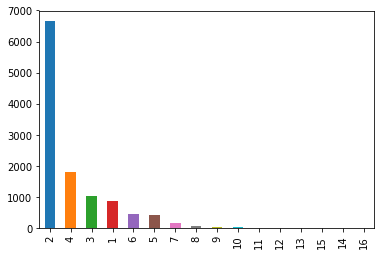

In [23]:
legs_distr = df_car.copy()
legs_distr.groupby(['IndividualID', 'TravDay']).TripID.count().value_counts().plot('bar')

In [24]:
df_car.head(2)

,TripID,TravDay,IndividualID,MainMode_B04ID,TripPurpFrom_B01ID,TripPurpTo_B01ID,TripStart,TripEnd,NumStages,TripDisIncSW,WeightTrip
0,2012000007,6,2012000003,CarDriver,Home,Food shopping,600.0,620.0,1,5.0,1.359127
1,2012000008,6,2012000003,CarDriver,Food shopping,Home,720.0,740.0,1,5.0,1.359127


In [25]:
def fullTrip_includes_work(x):
    # Check if trip includes a leg to work    
    if 'Work' in x.values:
        return True
    return False

In [26]:
df = df_car.copy()
# For each person's travel day
df = df.sort_values(['IndividualID', 'TravDay', 'TripStart'])
dfg = df.groupby((['IndividualID', 'TravDay']))

dfs = []

# Column to identify full trips (full trip is the whole journey from home until back home)
fullTrip_id = 0

for k, g in dfg:
    df = g.copy()
    # Make sure trips in chronological order
    #df.sort_values('TripStart', inplace=True)
    df.reset_index(drop=True, inplace=True)
    # Count the times the indivual left and returned home
    depart_home = df['TripPurpFrom_B01ID'] == 'Home'
    returned_home = df['TripPurpTo_B01ID'] == 'Home'
    total_departs_home = sum(depart_home)
    total_returns_home = sum(returned_home)
    
    if total_departs_home==total_returns_home!=0:
        # The entries in the diary are consistent
        # We'll slice the df so that the first trip is a departure from home trip
        # and last a return to home
        idx_begin_fullTrip = df.index[df['TripPurpFrom_B01ID'] == 'Home'].tolist()[0]
        idx_end_fullTrip = df.index[df['TripPurpTo_B01ID'] == 'Home'].tolist()[-1]
        
        df = df.iloc[idx_begin_fullTrip:idx_end_fullTrip+1].copy()
        
        df['FullTripID'] = fullTrip_id
        fullTrip_id += 1
        dfs.append(df)

df = pd.concat(dfs)
df.reset_index(drop=True, inplace=True)

includes_work = df.groupby('FullTripID')['TripPurpTo_B01ID'].transform(fullTrip_includes_work)
df['IncludesWork'] = includes_work

In [27]:
df_base = df.copy()

In [28]:
df.head(2)

,TripID,TravDay,IndividualID,MainMode_B04ID,TripPurpFrom_B01ID,TripPurpTo_B01ID,TripStart,TripEnd,NumStages,TripDisIncSW,WeightTrip,FullTripID,IncludesWork
0,2012000007,6,2012000003,CarDriver,Home,Food shopping,600.0,620.0,1,5.0,1.359127,0,False
1,2012000008,6,2012000003,CarDriver,Food shopping,Home,720.0,740.0,1,5.0,1.359127,0,False


In [29]:
dfg = df[['FullTripID', 'TripStart', 'TripEnd', 'TripDisIncSW', 'WeightTrip']]
dfg = df.groupby('FullTripID').agg({'TripStart': 'min', 'TripEnd': 'max', 'TripDisIncSW': 'sum', 'FullTripID': 'count'})
dfg.columns = ['TripStart', 'TripEnd', 'Distance', 'NumStages']
dfg

,TripStart,TripEnd,Distance,NumStages
FullTripID,,,,
0,600.0,740.0,10.00,2
1,515.0,1035.0,11.10,7
2,510.0,960.0,8.80,4
3,515.0,995.0,15.40,5
4,515.0,960.0,10.60,5
5,515.0,960.0,8.90,5
6,375.0,440.0,1.60,2
7,380.0,445.0,1.60,2
8,1095.0,1165.0,1.60,2


In [36]:
dist_bins = [0, 10, 25, 50, 100, 9999999]
dist_labels = prepare_dist_labes_from_bins(dist_bins)

In [30]:
cutter = [dfg.NumStages,
          pd.cut(dfg.Distance, dist_bins),
          pd.cut(dfg.TripStart, [0, 420, 600, 960, 1140, 1440], labels=['OP1', 'AM', 'IP', 'PM', 'OP2']),
          pd.cut(dfg.TripEnd, [0, 420, 600, 960, 1140, 1440], labels=['OP1', 'AM', 'IP', 'PM', 'OP2'])]

distr = dfg.groupby(cutter)['NumStages'].count()
distr.name = 'Trips'

In [31]:
distr_perc = distr.div(distr.sum())
distr_perc.name = 'Percentage'

In [32]:
distr_perc.groupby(level=0).sum()

NumStages
2     0.637592
3     0.081880
4     0.169608
5     0.036604
6     0.044368
7     0.014924
8     0.007865
9     0.002622
10    0.002118
11    0.001109
12    0.000807
13    0.000303
14    0.000101
16    0.000101
Name: Percentage, dtype: float64

In [33]:
# Over 90% between 1 and 5 legs
distr_perc.loc[idxslc[1:5]].sum()

0.9256831703136029

In [34]:
# Create the distribution for below 6 legs
distr_5legsmax = distr.loc[idxslc[1:5]].copy()
distr_5legsmax_perc = distr_5legsmax.div(distr_5legsmax.sum())
distr_5legsmax_perc

NumStages  Distance       TripStart  TripEnd
2          (0, 10]        OP1        OP1        0.000980
                                     AM         0.004139
                                     IP         0.011220
                                     PM         0.010784
                                     OP2        0.004031
                          AM         AM         0.027669
                                     IP         0.071242
                                     PM         0.066013
                                     OP2        0.009913
                          IP         IP         0.134749
                                     PM         0.051307
                                     OP2        0.014924
                          PM         PM         0.024837
                                     OP2        0.036710
                          OP2        OP2        0.024183
           (10, 25]       OP1        OP1        0.000327
                                     AM    

In [202]:
distr_5legsmax_perc_filt_low = distr_5legsmax_perc[distr_5legsmax_perc>=0.0]
distr_5legsmax_perc_filt_low.sum()

0.9999999999999999

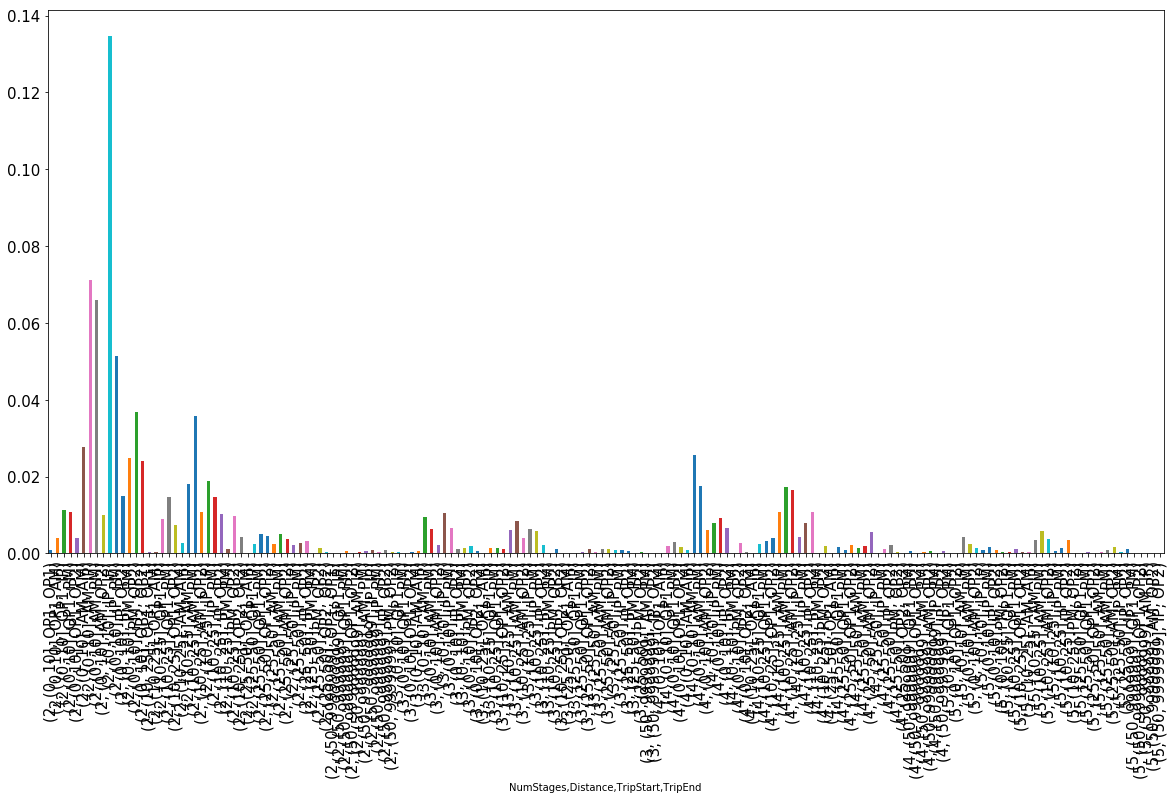

In [203]:
distr_5legsmax_perc_filt_low.plot('bar', figsize=(20,10), fontsize=15)

In [204]:
distr_perc.to_csv('nts_tripchains_distribution.csv', header=True)

In [ ]:
########################################################################

In [30]:
grpby_cols = ['FullTripID']
d_aggrs = {'NumStages':sum, 'TripStart': min, 'TripEnd': max, 'TripDisIncSW': sum, 'IncludesWork': 'first'}
df = df_base.groupby(grpby_cols, as_index=False).agg(d_aggrs)
df['TripDuration'] = df.TripEnd - df.TripStart
df.drop(columns=['TripStart', 'TripEnd'], inplace=True)
df

,FullTripID,NumStages,TripDisIncSW,IncludesWork,TripDuration
0,0,2,10.00,False,140.0
1,1,7,11.10,False,520.0
2,2,4,8.80,False,450.0
3,3,5,15.40,False,480.0
4,4,5,10.60,False,445.0
5,5,5,8.90,False,445.0
6,6,2,1.60,False,65.0
7,7,2,1.60,False,65.0
8,8,2,1.60,False,70.0
9,9,2,10.00,False,45.0


In [31]:
cutter = [df.NumStages,
          pd.cut(df.TripDisIncSW, list(np.arange(0, 50, 5))),
          pd.cut(df.TripDuration, list(np.arange(0, 24*60, 60)))]

df.groupby(cutter)['FullTripID'].count()

NumStages  TripDisIncSW  TripDuration
2          (0, 5]        (0, 60]         771
                         (60, 120]       752
                         (120, 180]      330
                         (180, 240]      120
                         (240, 300]       80
                         (300, 360]       55
                         (360, 420]       56
                         (420, 480]       41
                         (480, 540]       88
                         (540, 600]      107
                         (600, 660]       76
                         (660, 720]       21
                         (720, 780]       31
                         (780, 840]        9
                         (840, 900]        6
                         (900, 960]        4
                         (960, 1020]       1
           (5, 10]       (0, 60]         174
                         (60, 120]       397
                         (120, 180]      314
                         (180, 240]      160
                 

## Individuals data

In [ ]:
indivs = nts['Individual'].copy()

In [ ]:
df = indivs[['SurveyYear', 'Sex_B01ID', 'Age_B04ID', 'IndIncome2002_B02ID']]
df.columns = ['SurveyYear', 'Sex', 'AgeBand', 'Income']
df = df[df.SurveyYear >= 2012]
#df.drop('SurveyYear', axis=1, inplace=True)
indivs_sex_age_income = df.copy()

## Joins

In [ ]:
trips = trips_mode_purp_timeperiod.copy()
indivs = indivs_sex_age_income.copy()

In [ ]:
# fetch the Individual's ID
trips_ids = nts['Trip'].IndividualID
trips = trips.join(trips_ids)

In [ ]:
joined = trips.join(indivs, on='IndividualID')

In [ ]:
joined.head()

In [ ]:
# Define groupby keys
d_timeperiods = {'AM': 'AM', 'IP': 'IP', 'PM': 'PM',
                 'EOP': 'OP', 'LOP': 'OP'}

keys_age = joined.AgeBand.cat.categories
vals_age = ['0-4', '11-16', '17-20', '21-29', '30-39', '40-49', '5-10', '50-59', '60-99']
d_age = dict(zip(keys_age, vals_age))

keys_income = joined.Income.cat.categories
vals_income = ['0-0', '0-25000', '25000-50000', '50000-99999']
d_income = dict(zip(keys_income, vals_income))

In [ ]:
d_income

In [ ]:
d_age

In [ ]:
joined.AgeBand.replace(d_age, inplace=True)
joined.Income.replace(d_income, inplace=True)
joined.TimePeriod.replace(d_timeperiods, inplace=True)

In [ ]:
grp_cols = ['Purpose', 'Mode', 'TimePeriod', 'Sex', 'AgeBand', 'Income']
grp = joined.groupby(grp_cols).WeighTrip.sum()

# Segment the population
grp_percs_cols = ['Purpose', 'Mode', 'TimePeriod']
grp_percs = grp.groupby(level=grp_percs_cols).apply(lambda x: x/x.sum())
grp_percs = grp_percs.reset_index()

# Convert to interval index
grp_percs.AgeBand = grp_percs.AgeBand.apply(lambda x: convert_to_interval(x, delim='-', closed='both'))
grp_percs.Income = grp_percs.Income.apply(lambda x: convert_to_interval(x, delim='-', closed='both'))

grp_percs.set_index(grp_cols, inplace=True)
grp_percs = grp_percs.squeeze()
grp_percs.name = 'Percs'